# RAG sencillo con BGE-M3 + Chroma + LangGraph

En el notebook anterior aprendimos a **buscar** textos parecidos a una pregunta.
Ahora damos un paso más y construimos un **RAG** (*Retrieval-Augmented Generation*):

1. **Recuperar**: buscamos en la base de datos vectorial los textos más relacionados con la pregunta.
2. **Generar**: le pasamos a un modelo de lenguaje (LLM) la pregunta **y** esos textos, y le pedimos que responda **solo** con esa información.

Para organizar los pasos usaremos **LangGraph**, una librería para construir "flujos" de IA como si fueran un diagrama.

> Notebook para aprender, no para producción: priorizamos que se entienda cada pieza.

## 0. Instalación

Después de instalar, **reinicia la sesión** (menú *Entorno de ejecución → Reiniciar sesión*) y continúa desde la siguiente celda.
Pueden salir avisos de dependencias en rojo: son inofensivos para este notebook.

Recomendado: activa la GPU (*Entorno de ejecución → Cambiar tipo de entorno → GPU T4*). BGE-M3 es más grande que el modelo del notebook anterior (~2,3 GB).

In [ ]:
%pip install sentence-transformers chromadb langgraph langchain-openai python-dotenv

## 1. Configurar el modelo de lenguaje (LLM)

Usamos **Gemini** a través de su API "compatible con OpenAI". La ventaja: si mañana cambiamos a otro proveedor
(o al proxy del centro), solo hay que cambiar `BASE_URL`, `MODELO` y la clave.

Guarda tu clave en los **Secretos de Colab** (icono de la llave 🔑 en la barra izquierda) con el nombre `GEMINI_API_KEY`.

In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

API_KEY = os.getenv("GOOGLE_API_KEY")

if API_KEY:
    print("¡API Key cargada correctamente!")
else:
    print("No se pudo encontrar la API Key. Revisa que el archivo .env esté en la ruta correcta.")

¡API Key cargada correctamente!


In [14]:
from langchain_openai import ChatOpenAI

# try:
#     from google.colab import userdata
#     API_KEY = userdata.get("GEMINI_API_KEY")
# except Exception:
#     from getpass import getpass
#     API_KEY = getpass("Introduce tu API key de Gemini: ")

BASE_URL = "https://generativelanguage.googleapis.com/v1beta/openai/"   # o la URL del proxy del centro
MODELO   = "gemini-3.6-flash"

llm = ChatOpenAI(model=MODELO, api_key=API_KEY, base_url=BASE_URL, temperature=0)

# Prueba rápida de que el LLM responde
print(llm.invoke("Di 'hola' en gallego, solo la palabra.").content)

Ola


## 2. Nuestros documentos

Los mismos del notebook anterior, más dos en **gallego**: BGE-M3 es multilingüe y queremos comprobarlo.

In [3]:
documentos = [
    {"id": "d1",  "categoria": "cocina",     "texto": "La paella valenciana se cocina con arroz, pollo, conejo, judía verde y azafrán."},
    {"id": "d2",  "categoria": "cocina",     "texto": "Para una buena tortilla de patatas, fríe las patatas a fuego lento antes de mezclarlas con el huevo."},
    {"id": "d3",  "categoria": "cocina",     "texto": "O polbo á feira sérvese sobre madeira con aceite de oliva, sal grosa e pemento."},
    {"id": "d4",  "categoria": "deporte",    "texto": "El Deportivo de La Coruña ganó la Liga en la temporada 1999-2000."},
    {"id": "d5",  "categoria": "deporte",    "texto": "Correr tres veces por semana mejora la resistencia cardiovascular."},
    {"id": "d6",  "categoria": "deporte",    "texto": "En baloncesto, un triple vale tres puntos si se lanza desde fuera de la línea."},
    {"id": "d7",  "categoria": "tecnologia", "texto": "Python es un lenguaje de programación muy usado en ciencia de datos e inteligencia artificial."},
    {"id": "d8",  "categoria": "tecnologia", "texto": "Una GPU acelera el entrenamiento de redes neuronales porque hace muchas operaciones en paralelo."},
    {"id": "d9",  "categoria": "tecnologia", "texto": "Git permite guardar versiones del código y trabajar en equipo sin pisarse los cambios."},
    {"id": "d10", "categoria": "viajes",     "texto": "Santiago de Compostela es el final del Camino de Santiago y su catedral es Patrimonio de la Humanidad."},
    {"id": "d11", "categoria": "viajes",     "texto": "Para volar con equipaje de mano, revisa las medidas máximas que permite la aerolínea."},
    {"id": "d12", "categoria": "viajes",     "texto": "Para visitar as Illas Cíes no verán hai que solicitar autorización á Xunta e reservar o barco."},
]

textos = [d["texto"] for d in documentos]
print(f"Tenemos {len(textos)} documentos")

Tenemos 12 documentos


## 3. Vectorizar con BGE-M3

**BGE-M3** (de BAAI) es un modelo de la familia BERT (basado en XLM-RoBERTa) entrenado específicamente para **recuperación**:
encontrar el texto que responde a una pregunta, no solo frases que dicen lo mismo.

- Multilingüe (más de 100 idiomas).
- Admite textos largos (hasta 8192 tokens).
- Cada texto se convierte en un vector de **1024** números.

In [4]:
from sentence_transformers import SentenceTransformer

modelo_emb = SentenceTransformer("BAAI/bge-m3")   # la primera vez tarda: descarga ~2,3 GB

vectores = modelo_emb.encode(textos, normalize_embeddings=True)
print("Forma de la matriz:", vectores.shape)   # (14 documentos, 1024 números)

/home/mike/iabd_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|████████████████████| 391/391 [00:00<00:00, 19517.91it/s]


Forma de la matriz: (12, 1024)


## 4. Guardar en Chroma

Igual que en el notebook anterior: id, vector, texto y metadatos.

In [5]:
import chromadb

cliente = chromadb.PersistentClient(path="./chroma_rag")

if "apuntes_rag" in [c.name for c in cliente.list_collections()]:
    cliente.delete_collection("apuntes_rag")

coleccion = cliente.create_collection(name="apuntes_rag", metadata={"hnsw:space": "cosine"})

coleccion.add(
    ids=[d["id"] for d in documentos],
    embeddings=vectores.tolist(),
    documents=textos,
    metadatas=[{"categoria": d["categoria"]} for d in documentos],
)
print("Documentos guardados:", coleccion.count())

Documentos guardados: 12


## 5. El RAG como un grafo (LangGraph)

LangGraph organiza el programa con tres ideas:

| Concepto | Qué es | En nuestro RAG |
|---|---|---|
| **Estado** | Una "ficha" con los datos que van pasando de un paso a otro | `pregunta`, `documentos`, `respuesta` |
| **Nodos** | Funciones: reciben el estado y devuelven lo que actualizan | `recuperar` y `generar` |
| **Aristas** | Flechas que dicen qué nodo va después | INICIO → recuperar → generar → FIN |

### 5.1 El estado

In [6]:
from typing import TypedDict

class Estado(TypedDict):
    pregunta: str
    documentos: list[dict]   # lo que encuentra la búsqueda
    respuesta: str           # lo que contesta el LLM

### 5.2 Nodo 1: recuperar

Vectoriza la pregunta **con el mismo modelo** que los documentos y pide a Chroma los `K` más parecidos.

In [7]:
K = 3   # cuántos documentos le pasamos al LLM

def recuperar(estado: Estado) -> dict:
    vector_pregunta = modelo_emb.encode([estado["pregunta"]], normalize_embeddings=True).tolist()
    res = coleccion.query(query_embeddings=vector_pregunta, n_results=K)

    encontrados = []
    for doc_id, texto, dist in zip(res["ids"][0], res["documents"][0], res["distances"][0]):
        encontrados.append({"id": doc_id, "texto": texto, "similitud": round(1 - dist, 2)})

    return {"documentos": encontrados}

### 5.3 Nodo 2: generar

Construimos el **prompt**: instrucciones + documentos recuperados + pregunta.
Las instrucciones son clave: le pedimos que **no invente** y que **cite** de qué documento saca cada dato.

In [8]:
INSTRUCCIONES = """Eres un asistente que responde preguntas usando ÚNICAMENTE los documentos proporcionados.
- Si la respuesta no está en los documentos, di: "No tengo esa información en los documentos."
- Indica entre corchetes el id del documento que usas, por ejemplo [d4].
- Responde en el mismo idioma en que está escrita la pregunta, de forma breve."""

def generar(estado: Estado) -> dict:
    contexto = "\n".join(f"[{d['id']}] {d['texto']}" for d in estado["documentos"])

    mensajes = [
        ("system", INSTRUCCIONES),
        ("human", f"DOCUMENTOS:\n{contexto}\n\nPREGUNTA: {estado['pregunta']}"),
    ]
    respuesta = llm.invoke(mensajes)
    return {"respuesta": respuesta.content}

### 5.4 Montar el grafo

In [9]:
from langgraph.graph import StateGraph, START, END

grafo = StateGraph(Estado)

grafo.add_node("recuperar", recuperar)
grafo.add_node("generar", generar)

grafo.add_edge(START, "recuperar")
grafo.add_edge("recuperar", "generar")
grafo.add_edge("generar", END)

rag = grafo.compile()

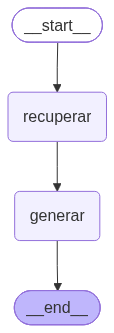

In [10]:
# Dibujamos el grafo para verlo
from IPython.display import Image, display
try:
    display(Image(rag.get_graph().draw_mermaid_png()))
except Exception:
    print(rag.get_graph().draw_mermaid())

## 6. Hacer preguntas

`rag.invoke(...)` recibe el estado inicial (solo la pregunta) y devuelve el estado final, ya relleno.
Mostramos también qué documentos se recuperaron, para ver **de dónde sale** la respuesta.

In [11]:
def preguntar(pregunta):
    estado_final = rag.invoke({"pregunta": pregunta})

    print(f" {pregunta}\n")
    print("Documentos recuperados:")
    for d in estado_final["documentos"]:
        print(f"   {d['similitud']:.2f} | [{d['id']}] {d['texto']}")
    print(f"\n{estado_final['respuesta']}")
    print("-" * 80)

In [15]:
preguntar("¿Qué ingredientes lleva la paella?")
preguntar("¿En qué año fue campeón de Liga el Dépor?")
preguntar("Que necesito para ir ás Illas Cíes en agosto?")   # pregunta en gallego

 ¿Qué ingredientes lleva la paella?

Documentos recuperados:
   0.69 | [d1] La paella valenciana se cocina con arroz, pollo, conejo, judía verde y azafrán.
   0.46 | [d3] O polbo á feira sérvese sobre madeira con aceite de oliva, sal grosa e pemento.
   0.42 | [d2] Para una buena tortilla de patatas, fríe las patatas a fuego lento antes de mezclarlas con el huevo.

La paella valenciana lleva arroz, pollo, conejo, judía verde y azafrán [d1].
--------------------------------------------------------------------------------
 ¿En qué año fue campeón de Liga el Dépor?

Documentos recuperados:
   0.53 | [d4] El Deportivo de La Coruña ganó la Liga en la temporada 1999-2000.
   0.27 | [d10] Santiago de Compostela es el final del Camino de Santiago y su catedral es Patrimonio de la Humanidad.
   0.21 | [d5] Correr tres veces por semana mejora la resistencia cardiovascular.

El Deportivo de La Coruña ganó la Liga en la temporada 1999-2000 [d4].
----------------------------------------------------

### ¿Y si preguntamos algo que no está en los documentos?

Un buen RAG debe **reconocer que no lo sabe** en lugar de inventar. Fíjate también en la similitud: es más baja.

In [16]:
preguntar("¿Cuál es la capital de Australia?")

 ¿Cuál es la capital de Australia?

Documentos recuperados:
   0.30 | [d10] Santiago de Compostela es el final del Camino de Santiago y su catedral es Patrimonio de la Humanidad.
   0.23 | [d5] Correr tres veces por semana mejora la resistencia cardiovascular.
   0.23 | [d6] En baloncesto, un triple vale tres puntos si se lanza desde fuera de la línea.

No tengo esa información en los documentos.
--------------------------------------------------------------------------------


### Comparación: el mismo LLM sin RAG

Sin documentos, el modelo responde con lo que "recuerda" de su entrenamiento: puede acertar, pero no sabemos de dónde lo saca
ni puede conocer información privada o reciente (por ejemplo, la normativa de un centro).

In [17]:
print(llm.invoke("¿Qué necesito para visitar las Islas Cíes en verano? Responde en una frase.").content)

Para visitar las Islas Cíes en verano necesitas solicitar la autorización previa y gratuita de la Xunta de Galicia y comprar el billete de barco con una naviera autorizada.


## 7. Para practicar

1. **Cambia `K`** a 1 y a 6. ¿Mejora o empeora la respuesta? ¿Qué pasa si le das documentos irrelevantes al LLM?
2. **Quita las instrucciones** de "no inventes" y vuelve a hacer la pregunta sobre Australia. ¿Qué cambia?
3. **Añade tus propios documentos** (por ejemplo, el horario o las normas del ciclo) y hazle preguntas.
4. **Añade un umbral**: en `recuperar`, descarta los documentos con similitud menor que 0,4. Si no queda ninguno, ¿qué debería hacer el LLM?
